# _Python for Scientific Data Analysis_


#  Matplotlib

## Section 2: Subplots and Axes Configurations (continued)

In [1]:
#preamble stuff
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import AutoMinorLocator

### Insets

You can also produce inset plots (plots within plots): the required commands within _matplotlib_ slightly differ depending on what you are trying to do.

Case 1: to just generate a plot-within-a-plot, you still need the ``plt.subplots()`` call initially to define the _fig_ and _axes_ containers.  To add a second plot _within_ a plot, you can call ``inset_figure=fig.add_axes([location and dimensions])``.   Here the numbers in brackets should refer to the starting x, starting y, width, and height of this inset plot.  E.g. ``left,bottom,width,height=[0.5,0.5,0.33,0.25]``.   Note that the units here are in relative dimensions of the entire plot (e.g. as seen in ``plt.show()``).   

Case 2: there are cases where you want the inset to be a _zoom-in_ of the primary plot: not plotting a separate thing.   In this case, the _matplotlib_ calls are different.     The call then is ``inset_figure=axes.inset_axes([x,y,width,height])`` and finally ``axes.indicate_inset_zoom(secondaxis)`` to show this second plot as a zoom-in of the major plot.

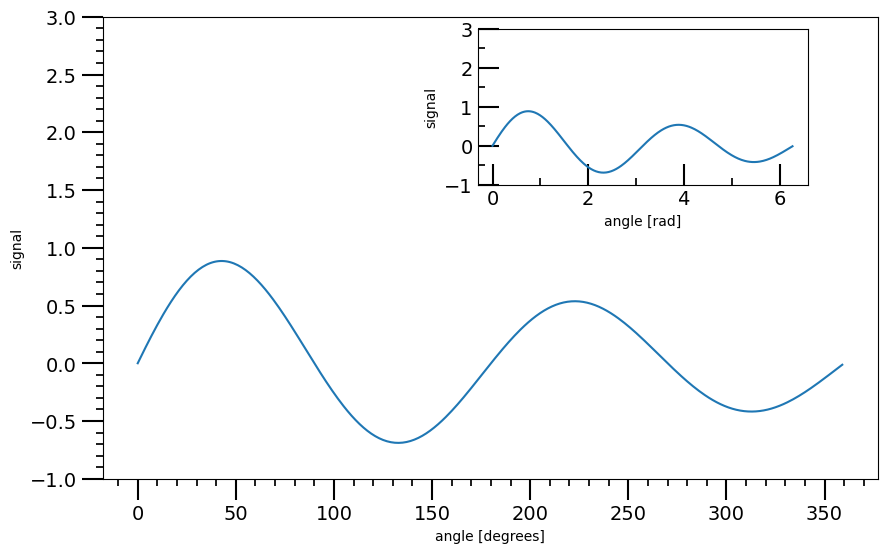

In [51]:


fig, ax = plt.subplots(figsize=(10,6))
x = np.arange(0, 360, 1) #array of degrees
#y = np.sin(((2 * x * np.pi)+np.pi) / 180) #y values
y = np.sin( 2 * x * np.pi / 180)*np.exp(-1*x/360) #y values

ax.plot(x, y)
ax.set_xlabel('angle [degrees]')
ax.set_ylabel('signal')
#ax.set_title('Sine wave')

ax.tick_params(which='both',width=1.5,direction='out',labelsize=14)
ax.tick_params(which='major',length=15,width=1.5)
ax.tick_params(which='minor',length=5,width=1.25)
ax.xaxis.set_minor_locator(AutoMinorLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))
ax.set_ylim(-1,3)

def deg2rad(x):
    return x * np.pi / 180

###IMPORTANT LINES

left,bottom,width,height=[0.5,0.6,0.33,0.26]

sec_ax=fig.add_axes([left,bottom,width,height])

sec_ax.set_ylabel('signal')
sec_ax.set_xlabel('angle [rad]')

sec_ax.plot(deg2rad(x),y)

sec_ax.set_ylim(-1,3)
sec_ax.tick_params(which='both',width=1.5,direction='in',labelsize=14)
sec_ax.tick_params(which='major',length=15,width=1.5)
sec_ax.tick_params(which='minor',length=5,width=1.25)
sec_ax.xaxis.set_minor_locator(AutoMinorLocator(2))
sec_ax.yaxis.set_minor_locator(AutoMinorLocator(2))


plt.show()

Below are two more examples from the SCExAO plots above: Case 1) we create an inset plot and redo the x and y axes to plot projected separation in au and contrast in magnitudes, respectively and Case 2) we create an inset plot that is a zoom-in. 

    

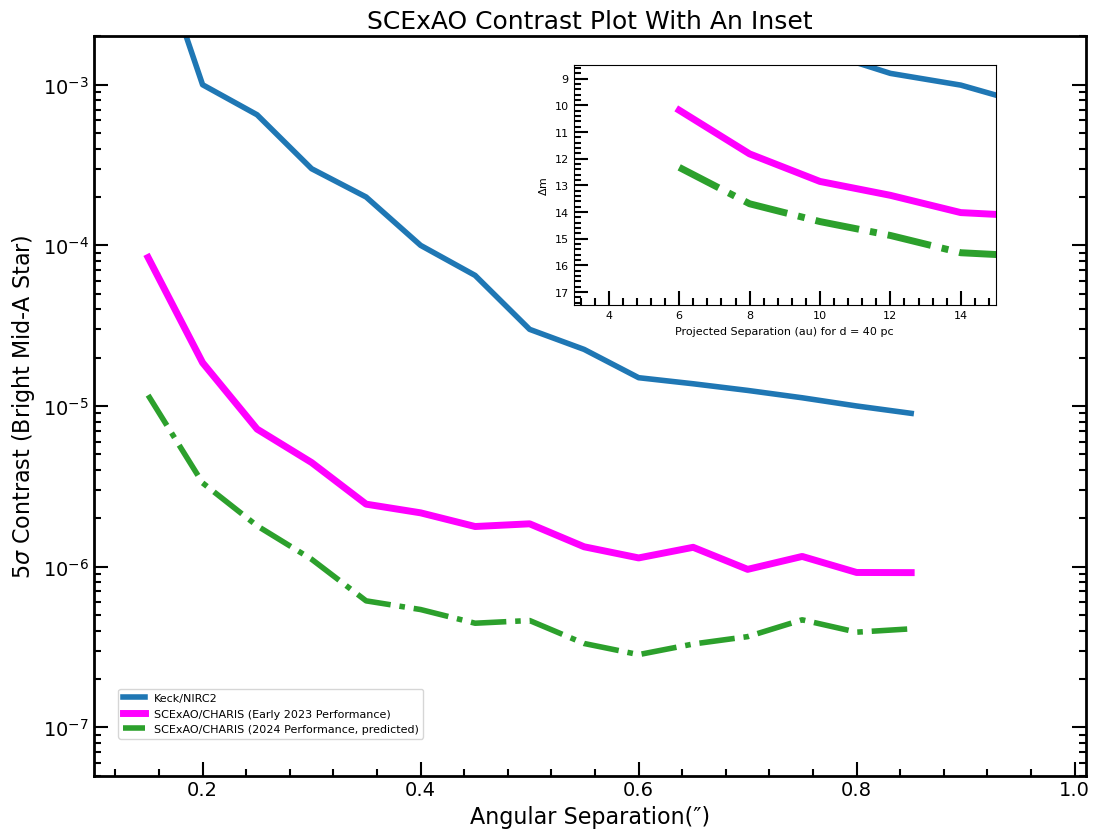

In [52]:
### Case 1(Ex_2.7)


# import matplotlib.pyplot as plot
# import numpy as np
# from scipy import interpolate
# from matplotlib.ticker import MultipleLocator,AutoMinorLocator,LogLocator

#file_in='./code/sect2/files/broadband_contrast.txt'
file_in='./files/broadband_contrast.txt'

dstar=40 #assume a distance of 40 pc
dtypes={'names':('angsep','contrast'), 'formats':(np.float64,np.float64)}

a = np.loadtxt(file_in,usecols=range(2),dtype=dtypes)
 #a=np.loadtxt(file_in)

ang_sep=a['angsep']
contrast_5sig=a['contrast']

nhour=2
scalefact=(nhour*3600/1800.)**(0.5)

fscexao=interpolate.interp1d(ang_sep,contrast_5sig/scalefact)

ang_sep_new=np.arange(0.15,0.9,0.05)
contrast_5sig_twohours=fscexao(ang_sep_new)


 #approximate performance for Keck/NIRC2

ang_sep_keck=np.array([0.15,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9])
contrast_keck=np.array([1e-2,1e-3,3e-4,1e-4,3e-5,1.5e-5,1.25e-5,1e-5,8e-6])

fkeck=interpolate.interp1d(ang_sep_keck,contrast_keck)
 #print(fkeck)
 #exit()
contrast_5sig_keck=fkeck(ang_sep_new)
 #estimate for new performance, SCExAO

improve_fact=4
contrast_5sig_twohours_new=contrast_5sig_twohours/improve_fact
igood=np.where(ang_sep_new < 0.25)
contrast_5sig_twohours_new[igood]/=(3-ang_sep_new[igood]*8.)
ibad=np.where(ang_sep_new > 0.7)
contrast_5sig_twohours_new[ibad]*=(1+1.75*ang_sep_new[ibad]-.7)

#print(ang_sep)

fig,axes=plt.subplots(figsize=(12.8,9.6))
axes.plot(ang_sep_new,contrast_5sig_keck,linewidth=4,markersize=np.sqrt(50),color='tab:blue',label='Keck/NIRC2')
axes.plot(ang_sep_new,contrast_5sig_twohours,linewidth=5,color='magenta',label='SCExAO/CHARIS (Early 2023 Performance)')
axes.plot(ang_sep_new,contrast_5sig_twohours_new,linewidth=4,ls='-.',color='tab:green',label='SCExAO/CHARIS (2024 Performance, predicted)')

axes.set_yscale('log')
axes.set_ylim(5e-8,2e-3)
axes.set_xlim(0.1,1.01)

#note: setting to 'both' instead of 'bottom' would draw tick marks at top of plot:
   #would mismatch with secondary axis tick marks
axes.xaxis.set_ticks_position('bottom')

axes.tick_params(labeltop=False,labelbottom=True,labelright=False,labelleft=True)
axes.tick_params(which='both',direction='in',labelsize=14)
axes.tick_params(which='major',length=10,width=1.5)
axes.tick_params(which='minor',length=5,width=1.5)
axes.xaxis.set_minor_locator(AutoMinorLocator(5))
 #log scale automatically sets minor tick marks to be reasonable here
axes.yaxis.set_ticks_position('both')

axes.set_ylabel(r'5$\sigma$ Contrast (Bright Mid-A Star)',fontsize=16)
axes.set_xlabel('Angular Separation(\u2033)',fontsize=16)
axes.set_title('SCExAO Contrast Plot With An Inset',fontsize=18)

###IMPORTANT LINES

left,bottom,width,height=[0.5,0.6,0.33,0.25]
secondaxis=fig.add_axes([left,bottom,width,height])
 

secondaxis.plot(dstar*ang_sep_new,-2.5*np.log10(contrast_5sig_keck),linewidth=4,markersize=np.sqrt(50),color='tab:blue')
secondaxis.plot(dstar*ang_sep_new,-2.5*np.log10(contrast_5sig_twohours),linewidth=5,color='magenta')
secondaxis.plot(dstar*ang_sep_new,-2.5*np.log10(contrast_5sig_twohours_new),ls='-.',linewidth=5,color='tab:green')
secondaxis.set_xlabel('Projected Separation (au) for d = 40 pc',fontsize=8)
secondaxis.set_ylabel(r'$\Delta$m',fontsize=8)
secondaxis.set_xlim(3,15)
secondaxis.set_ylim(17.5,8.5)
secondaxis.tick_params(which='both',direction='in',labelsize=8)
secondaxis.tick_params(which='major',length=10,width=1.5)
secondaxis.tick_params(which='minor',length=5,width=1.5)
secondaxis.xaxis.set_minor_locator(AutoMinorLocator(5))
secondaxis.yaxis.set_minor_locator(AutoMinorLocator(5))

 #thicken the spines
for axl in ['top','bottom','left','right']:
   axes.spines[axl].set_linewidth(2)

 #new legend location to avoid clashes
axes.legend(loc=[0.025,0.05],fontsize=8)

# plt.show()

#![](./code/sect2/figures/Ex2_7.png)

If the inset is using the same units as the primary axis (i.e. the inset is "zooming in") ... you can use ``axes.indicate_inset_zoom([secondaxis])`` to denote where on the main plot the zoomed-in region refers to.

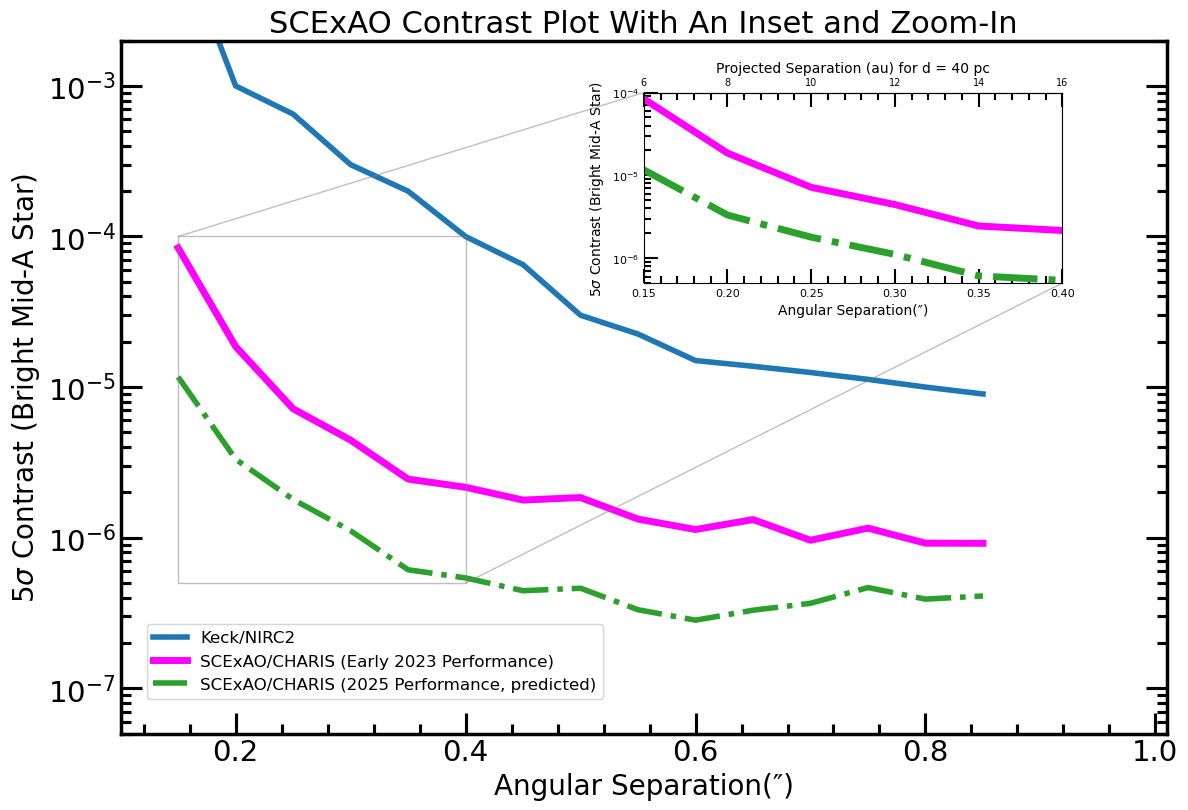

In [58]:
### Case 2(Ex_2.8)


# import matplotlib.pyplot as plot
# import numpy as np
# from scipy import interpolate
# from matplotlib.ticker import MultipleLocator,AutoMinorLocator,LogLocator



#import matplotlib.pyplot as plt
#import numpy as np

#from scipy import interpolate
#from mpl_toolkits.axes_grid.inset_locator import inset_axes
#from matplotlib.ticker import AutoMinorLocator


file_in='./files/broadband_contrast.txt'

dstar=40 #assume a distance of 40 pc
dtypes={'names':('angsep','contrast'), 'formats':(np.float64,np.float64)}

a = np.loadtxt(file_in,usecols=range(2),dtype=dtypes)
#a=np.loadtxt(file_in)

ang_sep=a['angsep']
contrast_5sig=a['contrast']

nhour=2
scalefact=(nhour*3600/1800.)**(0.5)

fscexao=interpolate.interp1d(ang_sep,contrast_5sig/scalefact)

ang_sep_new=np.arange(0.15,0.9,0.05)
contrast_5sig_twohours=fscexao(ang_sep_new)


#approximate performance for Keck/NIRC2

ang_sep_keck=np.array([0.15,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9])
contrast_keck=np.array([1e-2,1e-3,3e-4,1e-4,3e-5,1.5e-5,1.25e-5,1e-5,8e-6])

fkeck=interpolate.interp1d(ang_sep_keck,contrast_keck)
#print(fkeck)
#exit()
contrast_5sig_keck=fkeck(ang_sep_new)
#estimate for new performance, SCExAO

improve_fact=4
contrast_5sig_twohours_new=contrast_5sig_twohours/improve_fact
igood=np.where(ang_sep_new < 0.25)
contrast_5sig_twohours_new[igood]/=(3-ang_sep_new[igood]*8.)
ibad=np.where(ang_sep_new > 0.7)
contrast_5sig_twohours_new[ibad]*=(1+1.75*ang_sep_new[ibad]-.7)

#print(ang_sep)

scale=1.5
fig,axes=plt.subplots(figsize=(9*scale,6*scale))
#fig,axes=plt.subplots(figsize=(12.8,9))
axes.plot(ang_sep_new,contrast_5sig_keck,linewidth=4,markersize=np.sqrt(50),color='tab:blue',label='Keck/NIRC2')
axes.plot(ang_sep_new,contrast_5sig_twohours,linewidth=5,color='magenta',label='SCExAO/CHARIS (Early 2023 Performance)')
axes.plot(ang_sep_new,contrast_5sig_twohours_new,linewidth=4,ls='-.',color='tab:green',label='SCExAO/CHARIS (2025 Performance, predicted)')

axes.set_yscale('log')
axes.set_ylim(5e-8,2e-3)
axes.set_xlim(0.1,1.01)

#note:setting to 'both' instead of 'bottom' would draw tick marks at top of plot:
  #would mismatch with secondary axis tick marks
axes.xaxis.set_ticks_position('bottom')

axes.tick_params(labeltop=False,labelbottom=True,labelright=False,labelleft=True)
axes.tick_params(which='both',direction='in',labelsize=14*scale)
axes.tick_params(which='major',length=10*scale,width=1.5*scale)
axes.tick_params(which='minor',length=5*scale,width=1.5*scale)
axes.xaxis.set_minor_locator(AutoMinorLocator(5))
#log scale automatically sets minor tick marks to be reasonable here
axes.yaxis.set_ticks_position('both')

axes.set_ylabel(r'5$\sigma$ Contrast (Bright Mid-A Star)',fontsize=20)
axes.set_xlabel('Angular Separation(\u2033)',fontsize=20)
axes.set_title('SCExAO Contrast Plot With An Inset and Zoom-In',fontsize=22)

###IMPORTANTLINES

#secondaxis=inset_axes(axes,width=1.3,height=0.9,[0.5,0.6])
#secondaxis=axes.inset_axes([0.625, 0.65, 0.33, 0.25])
secondaxis=axes.inset_axes([0.5, 0.65, 0.4, 0.275]) #looks better in jupyter notebooks
#,width=1.3,height=0.9)
#left,bottom,width,height=[0.5,0.6,0.33,0.25]
#secondaxis=fig.add_axes([left,bottom,width,height])
#secondaxis=axes.secondary_xaxis('top',functions=(lambda x: dstar*x, lambda x: x/dstar))

secondaxis.plot(ang_sep_new,contrast_5sig_twohours,linewidth=5,color='magenta')
secondaxis.plot(ang_sep_new,contrast_5sig_twohours_new,ls='-.',linewidth=5,color='tab:green')
secondaxis.set_ylabel(r'5$\sigma$ Contrast (Bright Mid-A Star)',fontsize=10)
secondaxis.set_xlabel('Angular Separation(\u2033)',fontsize=10)
secondaxis.set_xlim(0.15,0.4) #watch what happens when you change the limits
secondaxis.set_ylim(5e-7,1e-4)
#secondaxis.set_ylim(5e-8,2e-3)
secondaxis.tick_params(which='both',direction='in',labelsize=8)
secondaxis.tick_params(which='major',length=10,width=1.5)
secondaxis.tick_params(which='minor',length=5,width=1.5)
secondaxis.xaxis.set_minor_locator(AutoMinorLocator(5))
#secondaxis.yaxis.set_minor_locator(AutoMinorLocator(5))
secondaxis.set_yscale('log')

secondary_axis2=secondaxis.secondary_xaxis('top',functions=(lambda x: dstar*x, lambda x: x/dstar))
secondary_axis2.set_xlabel('Projected Separation (au) for d = 40 pc',fontsize=10)
secondary_axis2.tick_params(which='both',direction='in',labelsize=7)
secondary_axis2.tick_params(which='major',length=10,width=1.5)
secondary_axis2.tick_params(which='minor',length=5,width=1.5)
secondary_axis2.xaxis.set_minor_locator(AutoMinorLocator(5))

axes.indicate_inset_zoom(secondaxis)

for axl in ['top','bottom','left','right']:
  axes.spines[axl].set_linewidth(2.5)

axes.legend(loc=[0.025,0.05],fontsize=12)

### Annotations

You can annotate a plot with text and arrows.  For simple text markup, the most straightforward way is to use ``axes.text(x,y,text,ha=ha,va=va,transform=transform``, which has accepts x and y positions, your text, vertical and horizontal alignment (ha, va), and a mapping between the coordinates and the plot (transform).  Note "transform" can correspond to axis coordinates or data coordinates depend on what you set.  The API for _text_ is here [https://matplotlib.org/stable/api/_as\_gen/matplotlib.axes.Axes.text.html]().

Arrows are common markers.  The most straightforward way to draw an arrow is with ``axes.arrow(x,y,dx,dy,width=width,transform=transform,color=color,fill=[True/False])``, where the full API is given here:
[https://matplotlib.org/stable/api/_as\_gen/matplotlib.axes.Axes.arrow.html]().   Note there are fancy ways of overplotting a _circle_  but to me the simplest way is to call ``axes.scatter`` and setting the color to 'none' and symbol size _s_ to a large number.

For something more involved, ``axes.annotate`` is what you want.  The API for _annotate_ is here: [https://matplotlib.org/stable/api/_as\_gen/matplotlib.pyplot.annotate.html]() . It can accept text and properties for arrows connecting the text to the end points, usually with a dictionary of values for the arrow properties.   One of the key ones is the _connectionstyle_ property, which will allow you to draw different kinds of connecting lines with an arrowhead at the end.  The API for connection styles is here: [https://matplotlib.org/stable/gallery/userdemo/connectionstyle\_demo.html]()

If we simply want to write something, then ``axes.text`` will work.  Note here the syntax is

``axes.text([x location],[y location],[string],ha=[horizontal alignment],va=[vertical alignment])``.

The full range of annotations you can do is quite vast, see here: [https://matplotlib.org/stable/gallery/text_labels_and_annotations/annotation_demo.html]() .  For example ...

``ax.arrow(3,2,1,1,arrowprops=dict(color='red',arrowstyle="-->",connectionstyle=angle3,angleA=0,angleB=-90``, will draw a curved arrow from [x,y]=(3,2) with x and y lengths of 1.

Below, we draw two arrows using ``arrow`` and ``annotate`` and add some text annotation.

(-2.0, 2.0)

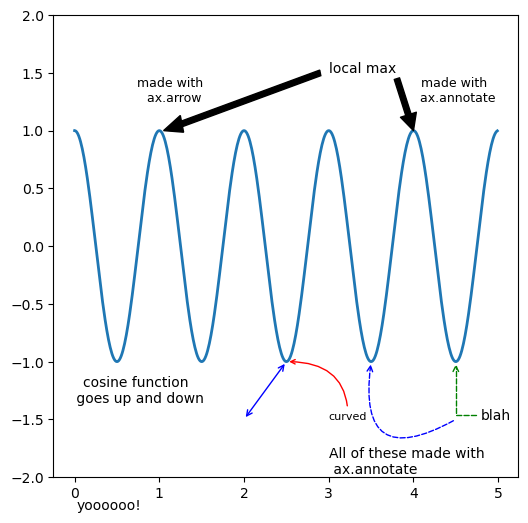

In [52]:
fig, ax = plt.subplots(figsize=(6, 6))

t = np.arange(0.0, 5.0, 0.01)
s = np.cos(2*np.pi*t)
line, = ax.plot(t, s, lw=2)

ax.annotate('local max', xy=(4, 1), xytext=(3, 1.5),
            arrowprops=dict(facecolor='black', shrink=0.0))
ax.arrow(2.9,1.5,-1.85,-0.5,width=0.05,length_includes_head=True,color='black',fill=True)

#using annotate to make arrows
ax.annotate("curved",xytext=(3,-1.5),xy=(2.5,-1),fontsize=8,
               arrowprops=dict(color='red',arrowstyle="->",connectionstyle="angle3,angleA=90,angleB=0"))
ax.annotate("",xytext=(2.,-1.5),xy=(2.5,-1),
                arrowprops=dict(color='blue',arrowstyle="<->",connectionstyle="arc,angleA=0,angleB=-0"))
ax.annotate("",xytext=(4.5,-1.5),xy=(3.5,-1),
                arrowprops=dict(color='blue',arrowstyle="->",linestyle='--',connectionstyle="arc3,rad=-1"))
ax.annotate("blah",xytext=(4.8,-1.5),xy=(4.5,-1),
                 arrowprops=dict(color='green',arrowstyle="->",linestyle='--',connectionstyle="angle,angleA=0,angleB=-90"))
#ax.annotate("",xytext=(3,-1.5),xy=(2.5,-1),arrowprops=dict(facecolor='red',arrowstyle="->",connectionstyle="angle3,angleA=0,angleB=-90"))
#ax.arrow(3,2,1,1,arrow_props=dict(facecolor='red'))
#,arrowstyle="->",connectionstyle="angle3,angleA=0,angleB=-90"))
         
ax.text(0.75,-1.25, 'cosine function \n goes up and down',ha='center',va='center')
ax.text(1.15,1.35, 'made with \n ax.arrow',ha='center',va='center',fontsize=9)
ax.text(4.5,1.35, 'made with \n ax.annotate',ha='center',va='center',fontsize=9)
ax.text(3,-2,'All of these made with \n ax.annotate',ha='left',va='bottom',fontsize=10)
ax.text(0.02,-2.25, 'yoooooo!',ha='left',va='center')
ax.set_ylim(-2, 2)

#here, "shrink" = move the tip and base some percent away from the annotated point and text

Here is one modification to our previous plot that illustrates several different kinds of annotations: simple text, _annotate_ with just a straight line (done three times), _arrow_, and _annotate_ done once with a complex connection style.

                                                                                                                          

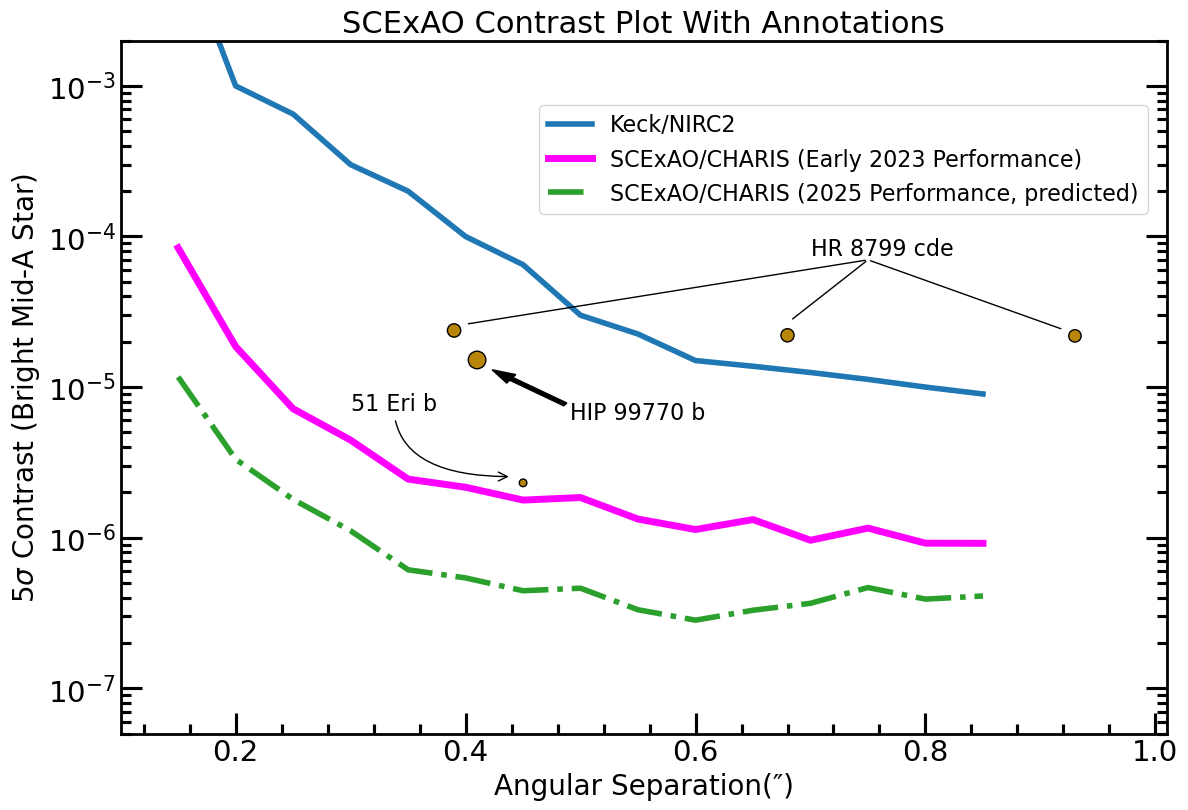

In [15]:
#Ex 2.9

from scipy import interpolate


###start: "bunch of math"
file_in='./files/broadband_contrast.txt'

dstar=40 #assume a distance of 40 pc
dtypes={'names':('angsep','contrast'), 'formats':(np.float64,np.float64)}

a = np.loadtxt(file_in,usecols=range(2),dtype=dtypes)
#a=np.loadtxt(file_in)

ang_sep=a['angsep']
contrast_5sig=a['contrast']

nhour=2
scalefact=(nhour*3600/1800.)**(0.5)

fscexao=interpolate.interp1d(ang_sep,contrast_5sig/scalefact)

ang_sep_new=np.arange(0.15,0.9,0.05)
contrast_5sig_twohours=fscexao(ang_sep_new)


#approximate performance for Keck/NIRC2

ang_sep_keck=np.array([0.15,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9])
contrast_keck=np.array([1e-2,1e-3,3e-4,1e-4,3e-5,1.5e-5,1.25e-5,1e-5,8e-6])

fkeck=interpolate.interp1d(ang_sep_keck,contrast_keck)
#print(fkeck)
#exit()
contrast_5sig_keck=fkeck(ang_sep_new)
#estimate for new performance, SCExAO

improve_fact=4
contrast_5sig_twohours_new=contrast_5sig_twohours/improve_fact
igood=np.where(ang_sep_new < 0.25)
contrast_5sig_twohours_new[igood]/=(3-ang_sep_new[igood]*8.)
ibad=np.where(ang_sep_new > 0.7)
contrast_5sig_twohours_new[ibad]*=(1+1.75*ang_sep_new[ibad]-.7)

#print(ang_sep)

### end: bunch of math

scale=1.5
fig,axes=plt.subplots(figsize=(9*scale,6*scale))
#fig,axes=plt.subplots(figsize=(12.8,9))
axes.plot(ang_sep_new,contrast_5sig_keck,linewidth=4,markersize=np.sqrt(50),color='tab:blue',label='Keck/NIRC2')
axes.plot(ang_sep_new,contrast_5sig_twohours,linewidth=5,color='magenta',label='SCExAO/CHARIS (Early 2023 Performance)')
axes.plot(ang_sep_new,contrast_5sig_twohours_new,linewidth=4,ls='-.',color='tab:green',label='SCExAO/CHARIS (2025 Performance, predicted)')

axes.set_yscale('log')
axes.set_ylim(5e-8,2e-3)
axes.set_xlim(0.1,1.01)

#note:setting to 'both' instead of 'bottom' would draw tick marks at top of plot:
  #would mismatch with secondary axis tick marks
axes.xaxis.set_ticks_position('bottom')

axes.tick_params(labeltop=False,labelbottom=True,labelright=False,labelleft=True)
axes.tick_params(which='both',direction='in',labelsize=14*scale)
axes.tick_params(which='major',length=10*scale,width=1.5*scale)
axes.tick_params(which='minor',length=5*scale,width=1.5*scale)
axes.xaxis.set_minor_locator(AutoMinorLocator(5))
#log scale automatically sets minor tick marks to be reasonable here
axes.yaxis.set_ticks_position('both')

axes.set_ylabel(r'5$\sigma$ Contrast (Bright Mid-A Star)',fontsize=20)
axes.set_xlabel('Angular Separation(\u2033)',fontsize=20)
axes.set_title('SCExAO Contrast Plot With Annotations',fontsize=22)

###IMPORTANTLINES
###IMPORTANTLINES
#secondaxis=axes.secondary_xaxis('top',functions=(lambda x: dstar*x, lambda x: x/dstar))

#secondaxis.set_xlabel('Projected Separation (au) for d = 40 pc',fontsize=16)
#secondaxis.tick_params(which='both',direction='in',labelsize=14)
#secondaxis.tick_params(which='major',length=10,width=1.5)
#secondaxis.tick_params(which='minor',length=5,width=1.5)
#secondaxis.xaxis.set_minor_locator(AutoMinorLocator(5))

#thicken the spines
for axl in ['top','bottom','left','right']:
  axes.spines[axl].set_linewidth(2)

axes.legend(loc=[0.4,0.75],fontsize=16)

planetnames=['HR 8799 e','HR 8799 d','HR 8799 c','51 Eri b','HIP 99770 b']
planetcontrast=10**(-0.4*(np.array([11.56,11.64,11.65,14.09,12.05])))
planetseps=np.array([0.39,0.68,0.93,0.45,0.41])
planetmass=np.array([9.2,9,8,3,16])

labeloffsetsx=np.array([0.01,0.0025,-0.01,-0.01,0.01])
labeloffsetsy=np.array([1.1,1.25,1.1,1.1,1.1])


axes.scatter(planetseps,planetcontrast,color='darkgoldenrod',edgecolor='black',s=100*planetmass/10,zorder=15)

#HR 8799 bcd labeling
axes.text(0.7,7.5e-5,'HR 8799 cde', fontsize=16)

for i in range(0,3):
 axes.annotate("",xy=(planetseps[i]+labeloffsetsx[i],labeloffsetsy[i]*planetcontrast[i]),xytext=(0.75,7.e-5),textcoords='data',arrowprops=dict(arrowstyle='-',facecolor='black'))

#HIP99770 b labeling

#note:we had to use transform=axes.transAxes because the y axis is a log plot.
axes.arrow(0.425,0.475,-0.07,0.05,width=0.005,transform=axes.transAxes,length_includes_head=True,color='black',fill=True)

#indata coordinates
#axes.text(0.55,6.8e-6,'HIP 99770 b',transform=axes.transData,ha='center',va='center',fontsize=16)
axes.text(0.55,6.8e-6,'HIP 99770 b',ha='center',va='center',fontsize=16)

#51Eri b
axes.annotate("51 Eri b",xy=(planetseps[-2]+labeloffsetsx[-2],
             labeloffsetsy[-2]*planetcontrast[-2]),xytext=(0.3,7e-6),
               textcoords='data',arrowprops=dict(arrowstyle='->',facecolor='black',
                connectionstyle="angle3,angleA=90,angleB=0"),fontsize=16);

